In [61]:
import glob
import os
import csv
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset, ConcatDataset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from transformers import AutoTokenizer, DistilBertForSequenceClassification

# Problem 1: Window Type Classification (CNN)

In [44]:
# A simple CNN model
class SimpleCNN(nn.Module):
  def __init__(self, num_classes):
    super(SimpleCNN, self).__init__()
    self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
    # BEGIN YOUR CODE HERE (~1 line)
    # Task 1 asks you to compute this input dimension BY HAND (channels
    # x height x width of conv3's pooled output, flattened) -- it is
    # deliberately not given to you here. Must match whatever you use in
    # the x.view(...) call in forward() below.
    self.fc1 = nn.Linear(2048, 512)
    # END YOUR CODE HERE
    self.fc2 = nn.Linear(512, num_classes)
    self.pool = nn.MaxPool2d(2, 2)

  def forward(self, x):
    x = self.pool(torch.relu(self.conv1(x)))
    x = self.pool(torch.relu(self.conv2(x)))
    x = self.pool(torch.relu(self.conv3(x)))
    # BEGIN YOUR CODE HERE (~1 line)
    # Same flattened size as fc1's input dimension above.
    x = x.view(-1, 2048)
    # END YOUR CODE HERE
    x = torch.relu(self.fc1(x))
    x = self.fc2(x)
    # x = torch.softmax(x, dim=1) <--- the bug for Task 2
    return x

## Task 1: Compute fc1's input dimension by hand

`SimpleCNN` above deliberately leaves `fc1`'s input dimension (and the matching `x.view(-1, ...)` call) blank. Compute it yourself: starting from the $32\times32\times3$ input, work out the output shape (channels $\times$ height $\times$ width) after `conv1`, its pooling layer, `conv2`, its pooling layer, `conv3`, and its pooling layer. Fill in the table below, then use the flattened size to fill in the two blanks in `SimpleCNN` above.

### Task 1 answer

_Fill in the shape after each layer, then compute the final flattened size. Double-click this cell to edit._

| layer | channels | height | width |
|---|---|---|---|
| input | 3 | 32 | 32 |
| conv1 | 32 | 32 | 32 |
| pool | 32 | 16 | 16 |
| conv2 | 64 | 16 | 16 |
| pool | 64 | 8 | 8 |
| conv3 | 128 | 8 | 8 |
| pool | 128 | 4 | 4 |

_Flattened size (channels $\times$ height $\times$ width) = (128 $\times$ 4 $\times$ 4) = 2048_

![](HW4_matthew_montero-1.jpg)

In [45]:
# Sanity check: fc1's shape doesn't depend on num_classes, so instantiate
# SimpleCNN with any placeholder value here and print its architecture --
# confirm the printed Linear(in_features=..., out_features=512) matches
# the flattened size you computed above.
print(SimpleCNN(num_classes=1))

SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=1, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)


In [46]:
# augmentation method can be added in training
# keep validation clean
train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

val_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset_dir = "data/train_set"

full_train_dataset = datasets.ImageFolder(root=dataset_dir, transform=train_transform)
full_val_dataset = datasets.ImageFolder(root=dataset_dir, transform=val_transform)  # same images, clean (no-augmentation) transform

# BEGIN YOUR CODE HERE (~4-8 lines)
# windows_test_set.zip ships unlabeled (see Problem 1's "About the test
# set" note) -- this train/val split is the ONLY way to get an accuracy
# number before final grading. Split the indices of full_train_dataset
# into disjoint train_idx/val_idx, stratified by class (each class
# should be represented proportionally in both splits). Hint: use
# full_train_dataset.targets, e.g. with
# sklearn.model_selection.train_test_split(..., stratify=...). A common
# split is 80% train / 20% val.
indices = list(range(len(full_train_dataset)))
train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=full_train_dataset.targets, random_state=42)
# END YOUR CODE HERE

train_dataset = Subset(full_train_dataset, train_idx)
val_dataset = Subset(full_val_dataset, val_idx)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1000, shuffle=False)


## Figure out the number of classes

Don't hardcode the number of classes anywhere below -- read it off of `train_dataset` itself.

In [47]:
# BEGIN YOUR CODE HERE (~1-2 lines)
# Figure out the number of classes directly from full_train_dataset (an
# ImageFolder) -- don't hardcode it. Hint: check what attributes an
# ImageFolder dataset exposes for its classes.
num_classes = len(full_train_dataset.classes)
# END YOUR CODE HERE

# Also load the human-readable class NAMES from the same folder
# structure (ImageFolder assigns each class an index based on its
# folder name, sorted alphabetically) -- useful later for labeling
# figures (e.g. Task 6's CAM overlays) instead of showing a raw index.
class_names = full_train_dataset.classes  # class_names[i] is the name for label i

print(f'Number of classes: {num_classes}')
print(f'Class names: {class_names}')

model = SimpleCNN(num_classes)
print(model)

Number of classes: 5
Class names: ['Awning', 'Bay', 'Fixed', 'H_Sliding', 'Hung']
SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=5, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)


## Task 2: Fix the bug and train the baseline

`SimpleCNN` has a bug involving how its output interacts with `nn.CrossEntropyLoss()` (used as the criterion below). Check the PyTorch documentation for what `nn.CrossEntropyLoss` expects as input, find and fix the bug in `SimpleCNN.forward` above, then run the cells below to train and evaluate.

In [48]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [49]:
# Explanation: The bug was the final line in the the foward function before the return statement,
# i.e., x = torch.softmax(x, dim=1). This is because nn.CrossEntropyLoss() requires raw logits;
# the last line was incorrect and can lead to the wrong loss calculation.

def train(model, train_loader, criterion, optimizer, num_epochs=5):
    model.train()
    for epoch in range(num_epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # you may consider to
        # save training log
        # save model checkpoints
        print(f"Epoch {epoch + 1}, Loss: {running_loss / len(train_loader)}")

train(model, train_loader, criterion, optimizer)
# Output:
# Epoch 1, Loss: 1.4930417944084515
# Epoch 2, Loss: 1.426962440664118
# Epoch 3, Loss: 1.285290089520541
# Epoch 4, Loss: 1.1279964650219136
# Epoch 5, Loss: 1.0264570252461866

Epoch 1, Loss: 1.4969960965893485
Epoch 2, Loss: 1.3937755525112152
Epoch 3, Loss: 1.227470262484117
Epoch 4, Loss: 1.1077036193825982
Epoch 5, Loss: 1.005550655451688


In [50]:
def evaluate(model, val_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f'Accuracy: {100 * correct / total}%')

evaluate(model, val_loader)

Accuracy: 56.312056737588655%


## Tasks 3 & 4: Receptive field of conv3's own output

Task 3 (compute by hand, no code needed) asks you to predict the receptive field of a unit in `conv3`'s own output feature map (right after `conv3`'s ReLU, but *before* its pooling layer), with respect to the $32\times32$ input.

Task 4 (below) asks you to verify this empirically: backprop a single unit's activation to the input image and see which pixels actually influenced it.

### Task 3 answer

_Fill in the table below, one row per layer (conv1, pool, conv2, pool, conv3, in order -- note conv3's own pooling layer is NOT part of this table, since we want the receptive field of conv3's output before it's pooled), then state your final conclusion underneath. Double-click this cell to edit._

| layer | $k$ | $s$ | $j_{\text{in}}$ | $RF_{\text{in}}$ | $j_{\text{out}}$ | $RF_{\text{out}}$ |
|---|---|---|---|---|---|---|
| conv1 | 3 | 1 | 1 | 1 | 1 | 3 |
| pool | 2 | 2 | 1 | 3 | 2 | 4 |
| conv2 | 3 | 1 | 2 | 4 | 2 | 8 |
| pool | 2 | 2 | 2 | 8 | 4 | 10 |
| conv3 | 3 | 1 | 4 | 10 | 4 | 18 |

_Conclusion: does the final receptive field cover the full $32\times32$ input? ..._
Answer: No, the final receptive field does not cover the entire $32\times32$ input because a single conv3 unit only covers an $18\times18$ region of the input.

![](HW4_matthew_montero-2.jpg)

In [9]:
# ===== Task 4: verify the receptive field empirically =====
# Pick ONE image, and ONE unit in conv3's OWN output feature map (i.e.,
# right after conv3's ReLU, but BEFORE conv3's pooling layer). Backprop
# that unit's activation to the input image, then look at which input
# pixels ended up with a nonzero gradient.

model.eval()

# grab a single image (batch size 1); we need requires_grad_ so that
# autograd tracks a gradient all the way back to the input pixels
image, label = val_dataset[0]
image = image.unsqueeze(0)
image.requires_grad_(True)

# BEGIN YOUR CODE HERE (~6-10 lines)
# 1. Run `image` through conv1 -> relu -> pool -> conv2 -> relu -> pool
#    -> conv3 -> relu (i.e., everything in SimpleCNN.forward up to and
#    including conv3's own ReLU, but NOT conv3's pooling layer, and NOT
#    the flatten + fc1 + fc2 head). You can reuse model.conv1/
#    model.conv2/model.conv3/model.pool directly. Call the resulting
#    feature map `fmap` -- it should have shape (1, 128, 8, 8).
x_conv1_relu_pool = model.pool(torch.relu(model.conv1(image)))
x_conv2_relu_pool = model.pool(torch.relu(model.conv2(x_conv1_relu_pool)))
fmap = torch.relu(model.conv3(x_conv2_relu_pool))
print(fmap.shape)

# 2. Pick one unit, e.g. fmap[0, c, h, w] for some (c, h, w) of your
#    choice (try c=1 and the center of the 8x8 grid first -- some
#    channel/location combinations sit at a dead ReLU for this image,
#    i.e. the activation is exactly 0, which blocks the gradient; if
#    that happens to you, try a different c).
h_choice = 4
w_choice = 4
for channel in range(fmap.shape[1]):
    if fmap[0, channel, h_choice, w_choice].item() != 0:
        c_choice = channel
        break

unit = fmap[0, c_choice, h_choice, w_choice]
print(unit)
print("c_choice:", c_choice, "h_choice:", h_choice, "w_choice:", w_choice)

# 3. Call .backward() on that single scalar unit (NOT on a loss!).
unit.backward()

# 4. Read off the gradient that ended up in `image.grad` -- it has the
#    same shape as `image`, (1, 3, 32, 32). Find which pixels have a
#    nonzero gradient, e.g.:
#    nonzero_mask = image.grad.abs().sum(dim=1).squeeze(0) > 1e-8
nonzero_mask = image.grad.abs().sum(dim=1).squeeze(0) > 1e-8
# END YOUR CODE HERE

# 5. Report the bounding box (min/max row, min/max col) of the nonzero
#    region below, and compare its size to your Task 3 answer.
rows = nonzero_mask.any(dim=1).nonzero().flatten()
cols = nonzero_mask.any(dim=0).nonzero().flatten()
if rows.numel() > 0 and cols.numel() > 0:
    print(f'Nonzero-gradient region: rows [{rows.min().item()}, {rows.max().item()}], '
          f'cols [{cols.min().item()}, {cols.max().item()}] '
          f'-> size {rows.max().item()-rows.min().item()+1} x {cols.max().item()-cols.min().item()+1}')
else:
    print('No nonzero-gradient pixels found -- this usually means the unit you picked was a '
          'dead ReLU (exactly 0) for this image, which blocks the gradient. Try a different '
          'channel c (or a different spatial location) and re-run this cell.')

# Output: Nonzero-gradient region: rows [9, 26], cols [9, 26] -> size 18 x 18
# Answer: This unit's receptive field has the same 18×18 region as the earlier calculated receptive field.

torch.Size([1, 128, 8, 8])
tensor(0.0190, grad_fn=<SelectBackward0>)
c_choice: 3 h_choice: 4 w_choice: 4
Nonzero-gradient region: rows [9, 26], cols [9, 26] -> size 18 x 18


## Task 5: Swap the head for Global Average Pooling

Replace the flatten + `fc1` + `fc2` head with Global Average Pooling followed by a single linear layer straight to `num_classes` logits.

In [10]:
# ===== Task 5: Global Average Pooling head =====
class SimpleCNN_GAP(nn.Module):
  def __init__(self, num_classes):
    super(SimpleCNN_GAP, self).__init__()
    self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
    self.pool = nn.MaxPool2d(2, 2)
    # BEGIN YOUR CODE HERE (~2 lines)
    # Add a Global Average Pooling layer (hint: nn.AdaptiveAvgPool2d
    # with output_size=1 does this in one line) and a SINGLE linear
    # layer mapping from 128 channels directly to num_classes.
    self.gap = nn.AdaptiveAvgPool2d(output_size=1)
    self.fc = nn.Linear(128, num_classes)
    # END YOUR CODE HERE

  def forward(self, x):
    x = self.pool(torch.relu(self.conv1(x)))
    x = self.pool(torch.relu(self.conv2(x)))
    fmap = self.pool(torch.relu(self.conv3(x)))  # shape (B, 128, 4, 4)
    # BEGIN YOUR CODE HERE (~3 lines)
    # Apply self.gap to `fmap`, reshape/squeeze the result to shape
    # (B, 128), then apply self.fc to get the final logits.
    x = self.gap(fmap)
    x = x.view(x.size(0), -1)
    logits = self.fc(x)
    # END YOUR CODE HERE
    return logits

gap_model = SimpleCNN_GAP(num_classes)
print(gap_model)

# Report parameter counts for both models, e.g.:
n_params_orig = sum(p.numel() for p in model.parameters())
n_params_gap = sum(p.numel() for p in gap_model.parameters())
print(f'SimpleCNN params: {n_params_orig}, SimpleCNN_GAP params: {n_params_gap}')
# Output: SimpleCNN params: 1144901, SimpleCNN_GAP params: 93893

# Now retrain: reuse train()/evaluate() from earlier, e.g.
gap_optimizer = optim.Adam(gap_model.parameters(), lr=0.001)
train(gap_model, train_loader, criterion, gap_optimizer)
evaluate(gap_model, val_loader)
# Output:
# Epoch 1, Loss: 1.4908693703738125
# Epoch 2, Loss: 1.4645946323871613
# Epoch 3, Loss: 1.435982584953308
# Epoch 4, Loss: 1.396104167808186
# Epoch 5, Loss: 1.3680123063650997
# Accuracy: 40.42553191489362%|

SimpleCNN_GAP(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=1)
  (fc): Linear(in_features=128, out_features=5, bias=True)
)
SimpleCNN params: 1144901, SimpleCNN_GAP params: 93893
Epoch 1, Loss: 1.4989081431518902
Epoch 2, Loss: 1.4780731905590405
Epoch 3, Loss: 1.444666781208732
Epoch 4, Loss: 1.4180604192343624
Epoch 5, Loss: 1.394520179791884
Accuracy: 39.148936170212764%


## Task 6: Class Activation Maps

Using your trained `gap_model` from Task 5, compute and visualize a Class Activation Map (CAM) for 3 correctly-classified test images.

torch.Size([1, 128, 4, 4])


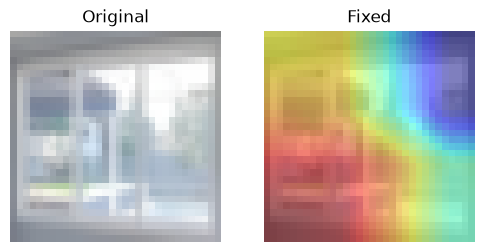

torch.Size([1, 128, 4, 4])


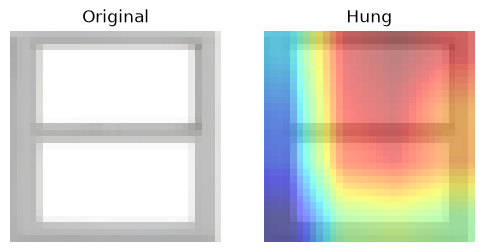

torch.Size([1, 128, 4, 4])


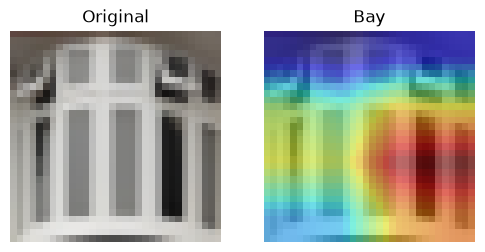

In [ ]:
# ===== Task 6: Class Activation Maps =====
def compute_cam(gap_model, image, predicted_class):
    """image: a single (1, 3, 32, 32) tensor. Returns a (4, 4) CAM (as a tensor)."""
    gap_model.eval()
    with torch.no_grad():
        image = image.unsqueeze(0)  # add batch dimension
        # BEGIN YOUR CODE HERE (~6-10 lines)
        # 1. Run `image` through conv1/pool, conv2/pool, conv3/pool
        #    (same three lines as in gap_model.forward) to get the last
        #    conv feature map `fmap`, shape (1, 128, 4, 4).
        x_conv1_relu_pool = gap_model.pool(torch.relu(gap_model.conv1(image)))
        x_conv2_relu_pool = gap_model.pool(torch.relu(gap_model.conv2(x_conv1_relu_pool)))
        fmap = gap_model.pool(torch.relu(gap_model.conv3(x_conv2_relu_pool)))
        print(fmap.shape)

        # 2. Get the weight vector for `predicted_class` from the GAP
        #    model's final linear layer: gap_model.fc.weight has shape
        #    (num_classes, 128); gap_model.fc.weight[predicted_class]
        #    has shape (128,).
        weight = gap_model.fc.weight[predicted_class]

        # 3. Compute the CAM as a weighted sum, over the 128 channels,
        #    of `fmap` using those weights -- i.e., for each of the 16
        #    (4x4) spatial positions: sum_k weight[k] * fmap[0, k, :, :].
        #    (Hint: torch.einsum('k,khw->hw', weight, fmap[0]) does this
        #    in one line; a broadcasted multiply + sum over dim 0 also
        #    works.)
        cam = torch.einsum("k,khw->hw", weight, fmap[0])

        # END YOUR CODE HERE
        return cam  # shape (4, 4)

def show_cam_overlay(image_tensor, cam, predicted_class, ax=None):
    """Upsamples `cam` to the image's resolution and overlays it as a heatmap.
    Uses `class_names` (loaded earlier from the dataset's folder names) to
    title the figure with a human-readable label instead of a raw index."""
    if ax is None:
        _, ax = plt.subplots(figsize=(1.5, 1.5))
    # BEGIN YOUR CODE HERE (~5-8 lines)
    # 1. Upsample `cam` (4x4) to (32, 32), e.g.:
    cam_up = F.interpolate(cam.view(1, 1, 4, 4), size=(32, 32),
                            mode='bilinear', align_corners=False)
    cam_up = cam_up.squeeze()

    # 2. Normalize cam_up to [0, 1] (e.g., (cam_up - cam_up.min()) /
    #    (cam_up.max() - cam_up.min() + 1e-8)) so it displays as a
    #    sensible heatmap regardless of the raw CAM value range.
    cam_up = (cam_up - cam_up.min()) / (cam_up.max() - cam_up.min() + 1e-8)

    # 3. Un-normalize `image_tensor` back to a displayable [0, 1] image
    #    (recall we normalized with mean=std=0.5, so displayed_img =
    #    image_tensor * 0.5 + 0.5)
    displayed_img = image_tensor * 0.5 + 0.5
    ax.imshow(displayed_img.permute(1, 2, 0).numpy())
    ax.imshow(cam_up.detach().numpy(), alpha=0.5, cmap='jet')
    
    # END YOUR CODE HERE
    ax.set_title(class_names[predicted_class])
    ax.axis('off')

# Pick 3+ correctly-classified test images (ideally from different
# predicted class), call compute_cam + show_cam_overlay(..., predicted_class)
# on each, and include the resulting figures in your submission.
selected = 0
selected_classes = set()
for inputs, labels in val_loader:
    # BEGIN YOUR CODE HERE 
    outputs = gap_model(inputs)
    _, predicted = torch.max(outputs, 1)
    # END YOUR CODE HERE 
    for i in range(len(labels)):
        # BEGIN YOUR CODE HERE (~6 lines)
        predicted_class = predicted[i].item()
        if selected < 3 and predicted_class not in selected_classes and predicted_class == labels[i]:
            image = inputs[i]
            cam = compute_cam(gap_model, image, predicted_class)

            fig, axes = plt.subplots(1, 2, figsize=(6, 3))

            displayed_img = image * 0.5 + 0.5

            axes[0].imshow(displayed_img.permute(1, 2, 0).numpy())
            axes[0].set_title("Original")
            axes[0].axis("off")

            show_cam_overlay(image, cam, predicted_class, ax=axes[1])

            plt.show()

            selected_classes.add(predicted_class)
            selected += 1
        # END YOUR CODE HERE 

In [12]:
# Save your trained GAP model's weights (e.g. to include in your
# submission, or to reload later without retraining).
torch.save(gap_model.state_dict(), 'gap_model.pth')
print('Saved gap_model weights to gap_model.pth')

Saved gap_model weights to gap_model.pth


## Task 7 (BONUS): Push past 60% accuracy

Using any combination of architecture changes, hyperparameter tuning, or changes to the training/optimization procedure, try to get your best model's test accuracy -- as computed by the TA from your submitted `predictions.csv` -- to at least 60%. A few directions to consider (you don't need all of them):

- **Architecture:** more conv layers or channels, `nn.BatchNorm2d`, `nn.Dropout`, or building on your `SimpleCNN_GAP` head from Task 5.
- **Hyperparameters:** learning rate, batch size, number of epochs, optimizer (e.g. `AdamW`, `SGD` with momentum), weight decay.
- **Training/optimization:** data augmentation in `train_transform` (e.g. `RandomHorizontalFlip`, `RandomRotation`, `ColorJitter`), a learning-rate scheduler, or a class-weighted loss (recall the class imbalance noted at the top of this problem).

In [57]:
# ===== Task 7 (BONUS): push past 60% accuracy =====
# Build your improved model/optimizer below, train it, and evaluate it
# on val_loader. Reuse train()/evaluate() from Task 2, or write your own
# training loop if you're using a scheduler or other custom logic.

class BonusCNN(nn.Module):
    def __init__(self, num_classes):
        super(BonusCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)
        self.dropout = nn.Dropout(p=0.2)
        # self.batchnorm = nn.BatchNorm2d(1024)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(1024, 512) # first argument: 256 x 2 x 2
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        x = self.pool(torch.relu(self.conv4(x)))
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(torch.relu(self.fc1(x)))
        x = self.dropout(torch.relu(self.fc2(x)))
        x = self.fc3(x)
        return x # logits
    

# BEGIN YOUR CODE HERE
criterion = nn.CrossEntropyLoss()
hyper_lrs = [1e-3] # I tried 0.01 and 0.0001 but both did bad
hyper_epochs = [5, 10, 15, 20]
torch.manual_seed(42)

best_configuration = {"learning_rate": hyper_lrs[0],
                      "epochs": hyper_epochs[0]}
best_accuracy = 0.0
    
for current_lr in hyper_lrs:
    for epochs in hyper_epochs:
        current_config = {"learning_rate": current_lr,
                          "epochs": epochs}
        print(f'Current learning rate: {current_config["learning_rate"]}, Current epochs: {current_config["epochs"]}')

        current_bonus_model = BonusCNN(num_classes)
        current_bonus_optimizer = optim.Adam(current_bonus_model.parameters(), lr=current_lr)

        train(current_bonus_model, train_loader, criterion, current_bonus_optimizer, num_epochs=epochs)

        current_bonus_model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                outputs = current_bonus_model(inputs)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        current_accuracy = correct / total
        print(f'Accuracy: {100 * current_accuracy}%')

        if current_accuracy > best_accuracy:
            best_configuration = current_config
            best_accuracy = current_accuracy
            best_bonus_model = current_bonus_model

# END YOUR CODE HERE

print(f'Best accuracy: {100 * best_accuracy}%, Best learning rate: {best_configuration["learning_rate"]}, Best epochs: {best_configuration["epochs"]}')
evaluate(best_bonus_model, val_loader)
# END YOUR CODE HERE

Current learning rate: 0.001, Current epochs: 5
Epoch 1, Loss: 1.5032184503295205
Epoch 2, Loss: 1.4793392609466205
Epoch 3, Loss: 1.3723393705758182
Epoch 4, Loss: 1.2600327161225406
Epoch 5, Loss: 1.1855246668512172
Accuracy: 50.638297872340424%
Current learning rate: 0.001, Current epochs: 10
Epoch 1, Loss: 1.538936820897189
Epoch 2, Loss: 1.4924134314060211
Epoch 3, Loss: 1.479262257164175
Epoch 4, Loss: 1.436569482088089
Epoch 5, Loss: 1.2955981222066013
Epoch 6, Loss: 1.2220618643543937
Epoch 7, Loss: 1.1622380709106273
Epoch 8, Loss: 1.103745394132354
Epoch 9, Loss: 1.0063247667117552
Epoch 10, Loss: 0.9111005812883377
Accuracy: 54.184397163120565%
Current learning rate: 0.001, Current epochs: 15
Epoch 1, Loss: 1.511897168376229
Epoch 2, Loss: 1.4828811911019413
Epoch 3, Loss: 1.3887887515804984
Epoch 4, Loss: 1.2503047395836224
Epoch 5, Loss: 1.1671818779273466
Epoch 6, Loss: 1.0823734348470515
Epoch 7, Loss: 1.0199822255156257
Epoch 8, Loss: 0.9390517283569683
Epoch 9, Loss: 0

### Task 7 answer

_Briefly describe what you changed and why (2-4 sentences). Double-click this cell to edit._
I chose to add an extra convolution/pool layer built off the SimpleCNN architecture to increase the final receptive field.
I think that increasing the RF would allow the incorporate more information with a larger region.
Because there are more parameters to train, I want to ensure it doesn't overfit so I added dropout on the forward pass.

## Submit predictions on the (unlabeled) test set

`windows_test_set.zip` ships without labels, so the cell below runs whichever of your trained models you consider best (swap in `model`, `gap_model`, or `bonus_model` as appropriate) over every image in `test_set/` and writes `predictions.csv`. Submit this file alongside your PDF -- the TA uses it to compute your real test accuracy, including whether you've met the bonus task's 60% threshold.

In [ ]:
class UnlabeledImageDataset(Dataset):
    """Loads every image file under `root` (searched recursively), with no
    label -- used for windows_test_set.zip, which ships unlabeled."""
    def __init__(self, root, transform):
        exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.gif')
        self.paths = sorted(
            p for ext in exts
            for p in glob.glob(os.path.join(root, '**', ext), recursive=True)
        )
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        image = Image.open(path).convert('RGB')
        return self.transform(image), os.path.basename(path)

test_dataset = UnlabeledImageDataset('data/test_set', val_transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Swap this for whichever of your trained models has the best validation
# accuracy (e.g. gap_model or bonus_model instead of model).
best_model = best_bonus_model # Using bonus model from bonus question
best_model.eval()

rows = []
with torch.no_grad():
    for images, filenames in test_loader:
        outputs = best_model(images)
        _, predicted = torch.max(outputs, 1)
        for fname, pred in zip(filenames, predicted.tolist()):
            rows.append((fname, class_names[pred]))

with open('predictions.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['filename', 'predicted_label'])
    writer.writerows(rows)

print(f'Wrote {len(rows)} predictions to predictions.csv')

Wrote 496 predictions to predictions.csv


# Problem 2: Comparing Vanilla RNN with Variants in Sequence Modeling

## Load the data

`X_train`/`X_test` are lists of variable-length sequences (each a `(seq_len, 10)` tensor); `y_train`/`y_test` are the corresponding scalar targets. Make sure `X_train.npy`, `y_train.npy`, `X_test.npy`, and `y_test.npy` (from `homework4_question2_data.zip`) are in the same directory as this notebook before running the cell below.

In [15]:
dataset_dir = 'data/sequential_data'

# load training and test data
def loadData():
    X_train = np.load(os.path.join(dataset_dir, 'X_train.npy'), allow_pickle=True)
    y_train = np.load(os.path.join(dataset_dir, 'y_train.npy'), allow_pickle=True)
    X_test = np.load(os.path.join(dataset_dir, 'X_test.npy'), allow_pickle=True)
    y_test = np.load(os.path.join(dataset_dir, 'y_test.npy'), allow_pickle=True)

    X_train = [torch.Tensor(x) for x in X_train]  # List of Tensors (SEQ_LEN[i], INPUT_DIM) i=0..NUM_SAMPLES-1
    X_test = [torch.Tensor(x) for x in X_test]  # List of Tensors (SEQ_LEN[i], INPUT_DIM)
    y_train = torch.Tensor(y_train)  # (NUM_SAMPLES, 1)
    y_test = torch.Tensor(y_test)  # (NUM_SAMPLES, 1)

    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = loadData()
device = y_train.device

## Task 1 (4 points): Implement a Vanilla RNN

Implement a Vanilla RNN architecture by hand (weights are shared across time steps). **You are not allowed to use an RNN layer implementation from any library** (e.g. `nn.RNN`, `nn.RNNCell`) -- only basic layers like `nn.Linear`.

In [16]:
# Define a Vanilla RNN layer by hand
class RNNLayer(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(RNNLayer, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        # BEGIN YOUR CODE HERE (~3 lines)
        # Define the input-to-hidden weights (W_xh), hidden-to-hidden
        # weights (W_hh), and the activation function applied to their
        # combined output (a Vanilla RNN uses tanh).
        self.W_xh = nn.Parameter(torch.randn(self.input_size, self.hidden_size) * 0.01)
        self.W_hh = nn.Parameter(torch.randn(self.hidden_size, self.hidden_size) * 0.01)
        self.activation = nn.Tanh()
        # END YOUR CODE HERE

    def forward(self, x, hidden):
        # BEGIN YOUR CODE HERE (~1 line)
        # Combine the current input x and the previous hidden state,
        # then apply the activation function.
        hidden = self.activation(torch.matmul(x, self.W_xh) + \
                                 torch.matmul(hidden, self.W_hh))
        # END YOUR CODE HERE
        return hidden


# Define a sequence prediction model using the Vanilla RNN
class SequenceModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SequenceModel, self).__init__()
        self.hidden_size = hidden_size
        # BEGIN YOUR CODE HERE (~2 lines)
        self.rnn = RNNLayer(input_size, self.hidden_size)
        self.linear = nn.Linear(self.hidden_size, output_size)
        # END YOUR CODE HERE

    def forward(self, input_seq, seq_lengths):
        # BEGIN YOUR CODE HERE (~2 lines)
        # input_seq is a list of (seq_len_b, input_size) tensors, one per
        # sample in the batch (lengths may differ across samples).
        batch_size = len(input_seq)
        last_hidden = torch.zeros(batch_size, self.hidden_size).to(device)
        # END YOUR CODE HERE

        for b in range(batch_size):
            hidden = torch.zeros(self.hidden_size).to(device)

            # BEGIN YOUR CODE HERE (~3 lines)
            # Run the RNN layer forward, one timestep at a time, over
            # this sample's full sequence (its own seq_lengths[b] steps),
            # updating `hidden` each step.
            seq_length = seq_lengths[b]
            for t in range(seq_length):
                hidden = self.rnn(input_seq[b][t], hidden)
            # END YOUR CODE HERE

            # Store the last hidden state in the output tensor
            last_hidden[b] = hidden

        output = self.linear(last_hidden)
        return output

## Tasks 2 & 3 (4 points each): Fixed-length variants

`SequenceModelFixedLen` below is shared by both variants -- it is instantiated with `seq_len` set to the dataset's shortest sequence length for **Task 2 (truncated)**, and to the dataset's longest sequence length for **Task 3 (padded)**. Unlike `SequenceModel` above, each timestep gets its **own, non-shared** `RNNLayer` (`self.rnn_layers[t]`), so this model does not tie weights across time.

The constructor parameter `seq_len` is what caps how many timesteps of each sequence actually get processed: in `forward`, each sample only runs for `min(self.seq_len, seq_lengths[b])` steps, i.e. its own length, but never more than `seq_len`. Setting `seq_len` to the shortest training-sequence length (Task 2) therefore truncates every longer sequence down to that length. Setting `seq_len` to the longest sequence length (Task 3) never truncates anything -- every sample simply runs its own true length, which is exactly what "ignoring the padding" amounts to here (a shorter sample never reaches, let alone runs, the extra padded timesteps).

In [17]:
# Define a sequence prediction model for fixed length sequences, BUT NO SHARED WEIGHTS
class SequenceModelFixedLen(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, seq_len):
        super(SequenceModelFixedLen, self).__init__()
        self.hidden_size = hidden_size
        self.seq_len = seq_len
        # BEGIN YOUR CODE HERE (~2 lines)
        # Note: rnn_layers is wrapped in nn.ModuleList (not a plain
        # Python list) -- nn.Module only auto-registers submodules held
        # in its own attributes/containers like nn.ModuleList, so a bare
        # list here would make every one of these RNNLayers invisible to
        # model.parameters(), and the optimizer would silently never
        # update them.
        self.rnn_layers = nn.ModuleList([RNNLayer(input_size, self.hidden_size) for _ in range(self.seq_len)])
        self.linear = nn.Linear(self.hidden_size, output_size)
        # END YOUR CODE HERE

    def forward(self, input_seq, seq_lengths):
        batch_size = len(input_seq)
        last_hidden = torch.zeros(batch_size, self.hidden_size).to(device)

        for b in range(batch_size):
            hidden = torch.zeros(self.hidden_size).to(device)

            # BEGIN YOUR CODE HERE (~3 lines)
            # For Task 2 (truncated), self.seq_len is the shortest
            # sequence length, so every sample runs for exactly
            # self.seq_len steps. For Task 3 (padded), self.seq_len is
            # the longest sequence length; a sample shorter than that
            # should stop at its OWN true length (min(...) below handles
            # both cases -- this is your "ignore the padding" mechanism,
            # since a shorter sample simply never runs its remaining,
            # nonexistent timesteps).
            seq_length = min(self.seq_len, seq_lengths[b])
            for t in range(seq_length):
                hidden = self.rnn_layers[t](input_seq[b][t], hidden)
            # END YOUR CODE HERE

            # Store the last hidden state in the output tensor
            last_hidden[b] = hidden

        output = self.linear(last_hidden)
        return output

## Hyperparameters and training loop

In [18]:
# Define hyperparameters and other settings
input_size = 10  # Replace with the actual dimension of your input features
hidden_size = 64
output_size = 1
num_epochs = 10
learning_rate = 0.001
batch_size = 32

# Sequence lengths across the training set -- needed to pick seq_len for
# the Task 2 (shortest) and Task 3 (longest) SequenceModelFixedLen models.
seq_lengths = [seq.shape[0] for seq in X_train]
min_length = min(seq_lengths)
max_length = max(seq_lengths)

In [19]:
# Training loop
def train(model, num_epochs, lr, batch_size, X_train, y_train, seq_lengths):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Task 4 asks you to "monitor and record the training ... loss
    # curves" -- record the average loss per epoch here so you can plot
    # it later (see the plotting cell under Task 4).
    epoch_losses = []

    for epoch in range(num_epochs):
        running_loss = 0.0
        num_batches = 0
        for i in range(0, len(X_train), batch_size):
            inputs = X_train[i:i + batch_size]
            targets = y_train[i:i + batch_size]
            lengths = seq_lengths[i:i + batch_size]

            optimizer.zero_grad()
            outputs = model(inputs, lengths)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            num_batches += 1

        epoch_loss = running_loss / num_batches
        epoch_losses.append(epoch_loss)
        print(f'Epoch {epoch + 1}, Loss: {epoch_loss}')
    return model, epoch_losses

torch.manual_seed(42)

## Task 4 (4 points): Train all three models, then predict before you evaluate

Train the Vanilla RNN, the truncated (shortest-length) model, and the padded (longest-length) model, each using MSE loss for a fixed number of epochs. Monitor and record the training (and validation, if you set aside a validation split) loss curves for each model. `train(...)` returns `(model, epoch_losses)` -- capture both.

Then, *before* looking at test-set performance, predict the **ranking** of the three models by overall test MSE (best to worst). Justify your prediction using the actual mechanics of the three architectures (shared weights vs. fixed-length truncation vs. fixed-length padding) -- not just intuition.

In [20]:
# BEGIN YOUR CODE HERE
# Initialize and train the Vanilla RNN (SequenceModel).

model_vanilla = SequenceModel(input_size, hidden_size, output_size)
model_vanilla, epoch_losses_vanilla = train(model=model_vanilla,
                                            num_epochs=num_epochs, 
                                            lr=learning_rate,
                                            batch_size=batch_size, 
                                            X_train=X_train, 
                                            y_train=y_train, 
                                            seq_lengths=seq_lengths)

# END YOUR CODE HERE

Epoch 1, Loss: 0.0304447303712368
Epoch 2, Loss: 0.020306206792593002
Epoch 3, Loss: 0.014080679267644882
Epoch 4, Loss: 0.0095957375690341
Epoch 5, Loss: 0.006353703867644072
Epoch 6, Loss: 0.0040505070984363555
Epoch 7, Loss: 0.00251958541572094
Epoch 8, Loss: 0.00155323329847306
Epoch 9, Loss: 0.0009520204132422805
Epoch 10, Loss: 0.0005869928188621998


In [21]:
# BEGIN YOUR CODE HERE
# Initialize and train the Sequential NN fixing #timesteps to the
# minimum sequence length (SequenceModelFixedLen with seq_len=min_length).

model_trunc = SequenceModelFixedLen(input_size, hidden_size, 
                                    output_size, min_length)
model_trunc, epoch_losses_trunc = train(model=model_trunc, 
                                        num_epochs=num_epochs, 
                                        lr=learning_rate,
                                        batch_size=batch_size, 
                                        X_train=X_train, 
                                        y_train=y_train, 
                                        seq_lengths=seq_lengths)
# END YOUR CODE HERE

Epoch 1, Loss: 0.03436048902571201
Epoch 2, Loss: 0.025572212338447572
Epoch 3, Loss: 0.020301009379327297
Epoch 4, Loss: 0.016693551167845724
Epoch 5, Loss: 0.014183145798742771
Epoch 6, Loss: 0.012427430152893066
Epoch 7, Loss: 0.011279276981949806
Epoch 8, Loss: 0.010553570277988911
Epoch 9, Loss: 0.010119756981730461
Epoch 10, Loss: 0.009865902904421091


In [22]:
# BEGIN YOUR CODE HERE
# Initialize and train the Sequential NN fixing #timesteps to the
# maximum sequence length (SequenceModelFixedLen with seq_len=max_length).
# NOTE: it is OK to use torch.nn.utils.rnn.pad_sequence; make sure to
# set parameter batch_first correctly.

model_padded = SequenceModelFixedLen(input_size, hidden_size,
                                     output_size, max_length)
model_padded, epoch_losses_padded = train(model=model_padded,
                                          num_epochs=num_epochs,
                                          lr=learning_rate,
                                          batch_size=batch_size,
                                          X_train=X_train,
                                          y_train=y_train,
                                          seq_lengths=seq_lengths)

# END YOUR CODE HERE

Epoch 1, Loss: 0.009133531805127859
Epoch 2, Loss: 0.002275962675921619
Epoch 3, Loss: 0.0011919817538000644
Epoch 4, Loss: 0.0007775315502658487
Epoch 5, Loss: 0.000544346037786454
Epoch 6, Loss: 0.00038850766664836554
Epoch 7, Loss: 0.0003027613105950877
Epoch 8, Loss: 0.0002818329754518345
Epoch 9, Loss: 0.0002210918112541549
Epoch 10, Loss: 0.00020137024868745356


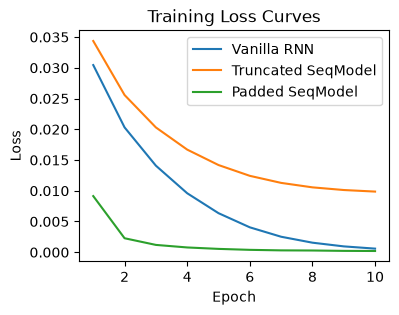

In [23]:
plt.figure(figsize=(4, 3))

# BEGIN YOUR CODE HERE
# Plot the recorded per-epoch training (and validation) loss curves for
# all three models on the same axes, for comparison.
plt.plot(range(1, num_epochs + 1), epoch_losses_vanilla, label='Vanilla RNN')
plt.plot(range(1, num_epochs + 1), epoch_losses_trunc, label='Truncated SeqModel')
plt.plot(range(1, num_epochs + 1), epoch_losses_padded, label='Padded SeqModel')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Curves')
plt.legend()

# END YOUR CODE HERE

### Task 4 answer

_Your predictions and justification here._
From best to worst:
1) Vanilla: It uses the same weight transformation for each input at each time step. 
            This reduces the number of learned parameters
            and allows the model to apply the same learned relationships across sequences of different lengths.
2) Padded: Having independent weights for each timesteps for up to max_length introduces more parameters than the vanilla.
            Not only would training take longer, but more parameters can lend the model
            to be prone to overfitting and worse at generalization.
3) Truncated: Unlike the other two, it throws away information from future timesteps by the shortest sequence.
                In turn, if there is relevant future information, the model would predict worse for long sequences,
                especially with independent weights for each timestep.

## Task 5 (4 points): Reconcile and analyze

Evaluate all three trained models on the test set and report the overall test MSE for each. Compare the actual ranking to your Task 4 prediction. Where you were right, explain why using the models' mechanics; where you were surprised, propose a concrete explanation. Discuss the trade-offs between shared weights, truncation, and padding for modeling sequences of varying length.

In [24]:
# BEGIN YOUR CODE HERE
# 1. Evaluate each of the three trained models on the test set (X_test,
#    y_test) using MSE. Compute FRESH sequence lengths from X_test
#    itself (e.g. test_seq_lengths = [seq.shape[0] for seq in X_test])
#    -- don't reuse the training set's seq_lengths variable, since it's
#    still in scope but describes the wrong sequences/order entirely.
test_seq_lengths = [seq.shape[0] for seq in X_test]
criterion = nn.MSELoss()

model_vanilla.eval()
model_padded.eval()
model_trunc.eval()

with torch.no_grad():
    predictions_vanilla = model_vanilla(X_test, test_seq_lengths)
    mse_vanilla = criterion(predictions_vanilla, y_test)

    predictions_padded = model_padded(X_test, test_seq_lengths)
    mse_padded = criterion(predictions_padded, y_test)

    predictions_trunc = model_trunc(X_test, test_seq_lengths)
    mse_trunc = criterion(predictions_trunc, y_test)

mse_results = {
    "Vanilla RNN": mse_vanilla.item(),
    "Padded SeqModel": mse_padded.item(),
    "Truncated SeqModel": mse_trunc.item()
}

# 2. Report the overall test MSE for each model, and the resulting
#    ranking (best to worst).
sorted_mse = sorted(mse_results.items(), key=lambda x: x[1])
print("Ranking (best to worst):")
for model, mse in sorted_mse:
    print(f"{model}: {mse}")

# END YOUR CODE HERE

Ranking (best to worst):
Vanilla RNN: 0.0005668042576871812
Padded SeqModel: 0.0007158570224419236
Truncated SeqModel: 0.00910536665469408


### Task 5 answer

My predictions were correct. Refer to explanations in my predicted.
I wasn't surprised that the truncated model did the worst, but I was surprised by how much badly it did;
it was by a higher order of magnitude. For working with some dataset of input sequences, an RNN is preferred..
Regarding tradeoffs, the truncated and padded models were as easy to implement than the vanilla RNN.
Moreover, the RNN was simpler to implement, though it required some more intuition.
For other tradeoffs, the vanilla RNN has a shared weight across timesteps so it can both predict better
and have less parameters to train; the other two have more to train on per timestep.
And while truncating reduces the params and increases training time,
it throws away potentially important future information. For padding, it can generalize worse due to extra params.


# Problem 3: Fine-tune a DistilBERT model

This starter code is organized so that all of the **data engineering** (downloading the dataset, splitting it, tokenizing it, wrapping it in `Dataset`/`DataLoader` objects) and the **generic training/evaluation loop** are already written for you and fully working -- you should not need to change any of that code. Cells marked **(given)** need no edits.

Your actual tasks (Tasks 1-7 plus the bonus) are about the modeling questions: what does freezing the backbone actually buy you, how do you tune a hyperparameter properly, and what is the model's attention actually doing. Each task below has a clearly marked `# BEGIN YOUR CODE HERE` / `# END YOUR CODE HERE` block -- that is the *only* place you need to write code for that task.

In [ ]:
# If you are running this notebook on Google Colab, uncomment the two
# lines below to connect to your Google Drive (e.g. to save model
# checkpoints so they survive after your Colab runtime disconnects).
# Nothing else in this notebook requires Drive -- the dataset is fetched
# directly from a public URL below -- so this cell is optional.

# from google.colab import drive
# drive.mount('/content/drive/')

## Setup (given)

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')  # Apple Silicon GPU
else:
    device = torch.device('cpu')
print(f'Using device: {device}')

# On MPS, the fused/SDPA attention kernel doesn't support dropout and
# raises `NotImplementedError: scaled_dot_product_attention for MPS does
# not support dropout` the instant you call .backward() in training mode.
# ATTN_IMPL picks a numerically-equivalent fallback on MPS; pass
# `attn_implementation=ATTN_IMPL` to every DistilBertForSequenceClassification
# .from_pretrained(...) call you write below (Tasks 3, 4, 5, and the Bonus),
# not just the one already given here.
ATTN_IMPL = 'eager' if device.type == 'mps' else 'sdpa'

Using device: mps


## Load and split the data (given)

The dataset is a set of ~10k COVID-era tweets, each labeled with whether it makes a medical claim (`label=1`) or not (`label=0`) -- this is the binary classification task described in the assignment. Note the dataset is fairly imbalanced (roughly 87% class 1, 13% class 0); keep that in mind when you look at raw accuracy vs. F1-macro later on.

In [3]:
# DATA_URL = 'https://raw.githubusercontent.com/LCS2-IIITD/LESA-EACL-2021/main/data/Twitter.csv'

df = pd.read_csv("Twitter.csv")
df = df.rename(columns={'tweet_text': 'text', 'claim': 'label'})
df = df.dropna(subset=['text', 'label']).reset_index(drop=True)
df['label'] = df['label'].astype(int)

print(f'Total examples: {len(df)}')
print(df['label'].value_counts(normalize=True))

# Stratified train/val/test split (70/15/15).
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=42)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42)

print(f'train: {len(train_df)}, val: {len(val_df)}, test: {len(test_df)}')

Total examples: 9981
label
1    0.87386
0    0.12614
Name: proportion, dtype: float64
train: 6986, val: 1497, test: 1498


## Tokenize and wrap in DataLoaders (given)

In [5]:
MODEL_NAME = 'distilbert-base-uncased'
MAX_LENGTH = 128
BATCH_SIZE = 32

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, attn_implementation=ATTN_IMPL)


class TweetDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        encodings = tokenizer(
            list(texts), padding='max_length', truncation=True,
            max_length=max_length, return_tensors='pt')
        self.input_ids = encodings['input_ids']
        self.attention_mask = encodings['attention_mask']
        self.labels = torch.tensor(labels.values, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids': self.input_ids[idx],
            'attention_mask': self.attention_mask[idx],
            'labels': self.labels[idx],
        }


train_dataset = TweetDataset(train_df['text'], train_df['label'], tokenizer, MAX_LENGTH)
val_dataset = TweetDataset(val_df['text'], val_df['label'], tokenizer, MAX_LENGTH)
test_dataset = TweetDataset(test_df['text'], test_df['label'], tokenizer, MAX_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Task 4 asks you to do a final training run on train+val combined.
trainval_dataset = ConcatDataset([train_dataset, val_dataset])
trainval_loader = DataLoader(trainval_dataset, batch_size=BATCH_SIZE, shuffle=True)

## Generic training/evaluation loop (given)

These three functions are reused, unchanged, by every task below. `train_for_epochs` prints validation F1-macro after every epoch so you can watch training progress; it works regardless of whether the backbone is frozen or not, since that's controlled entirely by which parameters you hand to the optimizer and by each parameter's own `requires_grad` flag -- not by anything in these functions.

In [6]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


@torch.no_grad()
def evaluate(model, loader):
    """Returns (f1_macro, all_preds, all_labels) over an entire loader."""
    model.eval()
    all_preds, all_labels = [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        preds = outputs.logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(batch['labels'].cpu().tolist())
    return f1_score(all_labels, all_preds, average='macro'), all_preds, all_labels


def train_for_epochs(model, train_loader, val_loader, optimizer, num_epochs):
    """Trains for num_epochs, printing train loss + val F1-macro each epoch."""
    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer)
        val_f1, _, _ = evaluate(model, val_loader)
        print(f'  epoch {epoch + 1}/{num_epochs} -- train loss: {train_loss:.4f}, val F1-macro: {val_f1:.4f}')
    return model


GRID_EPOCHS = 2   # epochs per grid-search setting (Task 3) -- kept short since you'll re-run this per setting
FINAL_EPOCHS = 3  # epochs for the final train+val runs (Tasks 4 and 5)

## Load the pretrained model (given)

**You will see a load report/warning listing some `UNEXPECTED` and `MISSING` keys -- this is expected, not an error:** `distilbert-base-uncased` is a checkpoint pretrained as a masked-language model, so it has MLM-specific weights (`vocab_transform`, `vocab_layer_norm`, `vocab_projector`) that don't exist in `DistilBertForSequenceClassification` and are safely dropped (`UNEXPECTED`); conversely, the classification head (`pre_classifier`, `classifier`) doesn't exist in the base checkpoint at all, so it is randomly initialized (`MISSING`). That randomly-initialized head is exactly what you'll be training in the tasks below.

In [7]:
model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2, attn_implementation=ATTN_IMPL)
model.to(device)
print(model)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

## REMOVED TASK
## Task 1 (3 points): Tensor shapes through your own model

The cell below (given) prints the configuration values you need -- note `model.config.dim` is the *combined* hidden size (before splitting into heads); divide by `n_heads` yourself to get the per-head size. These shapes come from the model's fixed architecture, not from training, so you can do this before any of the tasks below. Using `dim`, `n_heads`, `n_layers`, the batch size `B` (`BATCH_SIZE`), and `max_length` `L` (`MAX_LENGTH`), compute -- showing your work -- the six quantities (a)-(f) listed in the assignment (shapes of Q/K/V per-head and combined, the attention map, Dropout-1's output, the final Output, and the self-attention sub-layer's total parameter count as a formula and as a number).

In [ ]:
# Note: model.config.dim is the COMBINED hidden size (i.e., before
# splitting into heads) -- Q/K/V are each projected to this full size
# first; only afterward is that split into n_heads heads of size
# dim // n_heads each.
print(f'dim (combined hidden size, before splitting into heads): {model.config.dim}')
print(f'n_heads: {model.config.n_heads}')
print(f'n_layers: {model.config.n_layers}')
print(f'batch size B used for training: {BATCH_SIZE}')
print(f'max_length L used for training: {MAX_LENGTH}')

### Task 1 answer

_Fill in each shape/quantity below, showing your work. Double-click this cell to edit._

(a) Shape of Q, K, V (single head): ...

(b) Shape of Q, K, V (combined): ...

(c) Shape of the attention map: ...

(d) Shape of Dropout-1's output: ...

(e) Shape of Output: ...

(f) Total parameters in one self-attention sub-layer (formula, then a number for your model): ...

## Task 2 (3 points): Before you freeze anything

Inspect the model's structure via `model.named_parameters()` (or `print(model)`), then fill in the blanks:

(a) Compute the total number of parameters in the model, and separately the number of parameters belonging only to the classification head (`pre_classifier` and `classifier`) -- not the DistilBERT backbone.
(b) Based on these two counts, what fraction of the model's parameters will actually receive gradient updates if you freeze the backbone?
(c) In 1-2 sentences, predict how this should affect training speed and memory use compared to fine-tuning the whole model -- you will check this prediction in Task 5.

In [14]:
# BEGIN YOUR CODE HERE (~2 lines)
# (a) Compute the total number of parameters in `model`, and separately
#     the number of parameters in ONLY the classification head
#     (model.pre_classifier and model.classifier).
# Hint: a parameter tensor `p` has `p.numel()` elements; `model.named_parameters()`
# gives you (name, tensor) pairs, so you can tell head params apart from
# backbone params by whether the name starts with 'pre_classifier'/'classifier'.
total_params = sum([p.numel() for p in model.parameters()])
head_params = sum([p.numel() for name, p in model.named_parameters() 
                   if name.startswith("pre_classifier")
                   or name.startswith("classifier")])
# END YOUR CODE HERE
# print(model)

print(f'Total parameters: {total_params:,}')
print(f'Classification head parameters: {head_params:,}')
print(f'Fraction trainable if backbone is frozen: {head_params / total_params:.4%}')

Total parameters: 66,955,010
Classification head parameters: 592,130
Fraction trainable if backbone is frozen: 0.8844%


### Task 2 answer -- (b) and (c)

_Your fraction-trainable interpretation (b) and your speed/memory prediction (c) here._
- (b) 592,130 / 66,955,010 = 0.88%, or less than 1%
- (c) This should be very fast compared to training the whole model since only 1% of parameters are trained.
        However, there will be a lot of memory used for training on all parameters than just 1%.

## Task 3 (5 points): Grid search with a frozen backbone

Implement grid search for at least one hyperparameter (e.g., learning rate). For **each** setting:
1. Load a **freshly** pretrained model (do not reuse a model that already trained under a previous setting -- see the warning in the assignment).
2. Freeze every parameter in `model.distilbert` (the backbone) by setting `requires_grad=False`, so that only the classification head you identified in Task 2 will train.
3. Build an optimizer over *only* the head's trainable parameters (`filter(lambda p: p.requires_grad, model.parameters())` is one way to do this).
4. Train with `train_for_epochs(model, train_loader, val_loader, optimizer, GRID_EPOCHS)` and record the final validation F1-macro.

Report the F1-macro for every setting you tried and identify the best one.

In [18]:
# BEGIN YOUR CODE HERE (~12-18 lines)
learning_rates = [0.01, 0.001, 0.0001]  # try at least 3 values
grid_search_results = {}

for lr in learning_rates:
    print(f'--- learning rate = {lr} ---')
    # 1. Load a fresh pretrained model. Remember attn_implementation=ATTN_IMPL
    #    (see the Setup cell) -- needed for training to work at all on MPS.
    current_model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, 
                                                                        num_labels=2, 
                                                                        attn_implementation=ATTN_IMPL).to(device)

    # 2. Freeze every backbone parameter.
    for param in current_model.distilbert.parameters():
        param.requires_grad = False

    # 3. Build an optimizer over only the trainable (head) parameters.
    optimizer_partial = optim.Adam((p for p in current_model.parameters() if p.requires_grad), 
                                    lr=lr)

    # 4. Train, then record this setting's final validation F1-macro in
    #    grid_search_results[lr].
    current_model_trained = train_for_epochs(current_model, train_loader, val_loader, 
                                             optimizer_partial, GRID_EPOCHS)
    val_f1, val_preds, val_labels = evaluate(current_model_trained, val_loader)
    grid_search_results[lr] = val_f1
    print("lr:", lr, "val F1-macro:", val_f1)
    
    

# END YOUR CODE HERE

best_lr = max(grid_search_results, key=grid_search_results.get)
print(f'\nBest learning rate: {best_lr} (val F1-macro = {grid_search_results[best_lr]:.4f})')

# Results
# lr: 0.01 val F1-macro: 0.6579926068246424 ... 
# lr: 0.001 val F1-macro: 0.4973857051336729 ... 
# lr: 0.0001 val F1-macro: 0.5298366834170855 ... 
# Best learning rate: 0.01 (val F1-macro = 0.6580)

--- learning rate = 0.01 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 -- train loss: 0.3959, val F1-macro: 0.5160
  epoch 2/2 -- train loss: 0.3420, val F1-macro: 0.6580
lr: 0.01 val F1-macro: 0.6579926068246424
--- learning rate = 0.001 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 -- train loss: 0.3500, val F1-macro: 0.6073
  epoch 2/2 -- train loss: 0.3263, val F1-macro: 0.4974
lr: 0.001 val F1-macro: 0.4973857051336729
--- learning rate = 0.0001 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 -- train loss: 0.3699, val F1-macro: 0.4717
  epoch 2/2 -- train loss: 0.3376, val F1-macro: 0.5298
lr: 0.0001 val F1-macro: 0.5298366834170855

Best learning rate: 0.01 (val F1-macro = 0.6580)


## Task 4 (3 points): Final frozen-head training

Using `best_lr` from Task 3, load one more fresh pretrained model, freeze the backbone the same way, and train on **train+val combined** (`trainval_loader`, given above) for `FINAL_EPOCHS` epochs. Then evaluate its F1-macro on the **test** set -- this is the number you'll compare against Task 5. Save the model as `frozen_head_model`, its test F1-macro as `frozen_head_f1`, and the wall-clock training time (via `time.time()`) as `frozen_head_train_time`; you'll need all three later.

In [20]:
# BEGIN YOUR CODE HERE (~8 lines)
# Load a fresh pretrained model (remember attn_implementation=ATTN_IMPL,
# see the Setup cell), freeze the backbone, build an optimizer
# over the head parameters using best_lr, then train on trainval_loader
# for FINAL_EPOCHS epochs. Record start_time and end_time around the
# training call using time.time() (the given line below uses them to
# compute the elapsed training time), and save your trained model as
# frozen_head_model.


print(f'--- learning rate = {best_lr} ---')
# 1. Load a fresh pretrained model.
frozen_head_model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, 
                                                                        num_labels=2, 
                                                                        attn_implementation=ATTN_IMPL).to(device)

# 2. Freeze every backbone parameter.
for param in frozen_head_model.distilbert.parameters():
    param.requires_grad = False

# 3. Build an optimizer over only the trainable (head) parameters.
optimizer_frozen_final = optim.Adam((p for p in frozen_head_model.parameters() if p.requires_grad), 
                                    lr=best_lr)

# 4. Train, then record this setting's final validation F1-macro.
start_time = time.time()
frozen_head_model = train_for_epochs(frozen_head_model, trainval_loader, val_loader, 
                                     optimizer_frozen_final, FINAL_EPOCHS)
end_time = time.time()

frozen_head_train_time = end_time - start_time
frozen_head_f1, frozen_head_preds, frozen_head_labels = evaluate(frozen_head_model, test_loader)

print(f'Frozen-head model: test F1-macro = {frozen_head_f1:.4f}, training time = {frozen_head_train_time:.1f}s')

--- learning rate = 0.01 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/3 -- train loss: 0.3992, val F1-macro: 0.4824
  epoch 2/3 -- train loss: 0.3348, val F1-macro: 0.6341
  epoch 3/3 -- train loss: 0.3275, val F1-macro: 0.6232
Frozen-head model: test F1-macro = 0.6191, training time = 535.1s


In [ ]:
# Optional: training the Task 5 model on top of an already-loaded
# frozen_head_model can push you over your GPU's memory limit (e.g. a
# CUDA/MPS out-of-memory error, or your Colab runtime crashing). If that
# happens, uncomment the lines below to free frozen_head_model's memory
# before continuing -- frozen_head_f1 and frozen_head_train_time (both
# already saved above) are all Task 5 actually needs. Only do this if
# you're fine re-training frozen_head_model later, in case it turns out
# to be the better model for Task 6.

# import gc
# del frozen_head_model
# gc.collect()
# if device.type == 'cuda':
#     torch.cuda.empty_cache()
# elif device.type == 'mps':
#     torch.mps.empty_cache()

## Task 5 (3 points): Is freezing the backbone actually worth it?

Repeat the final training from Task 4, but this time **unfreeze every parameter** (leave `requires_grad=True` everywhere -- this is the default for a freshly loaded model, so simply skip the freezing step) and fine-tune the whole model, using a smaller learning rate suitable for full fine-tuning (e.g. `2e-5`). Train on `trainval_loader` for `FINAL_EPOCHS` epochs, exactly as in Task 4, and time it the same way. Save the model as `full_finetune_model`, its test F1-macro as `full_finetune_f1`, and its training time as `full_finetune_train_time`.

In [22]:
# BEGIN YOUR CODE HERE (~6 lines)
# Load a fresh pretrained model (remember attn_implementation=ATTN_IMPL,
# see the Setup cell; do NOT freeze anything this time), build
# an optimizer over ALL of its parameters with a small learning rate
# (e.g. 2e-5), then train on trainval_loader for FINAL_EPOCHS epochs.
# Record start_time and end_time using time.time() the same way as
# Task 4, and save your trained model as full_finetune_model.

print(f'--- learning rate = {2e-5} ---')
# 1. Load a fresh pretrained model.
full_finetune_model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, 
                                                                          num_labels=2, 
                                                                          attn_implementation=ATTN_IMPL).to(device)

# 3. Build an optimizer over only the trainable (head) parameters.
optimizer_full_finetune = optim.Adam((p for p in full_finetune_model.parameters()), 
                                     lr=2e-5)

trainable_params = sum(p.numel() for p in full_finetune_model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable_params:,}")

# 4. Train, then record this setting's final validation F1-macro.
start_time_full_finetune = time.time()
full_finetune_model = train_for_epochs(full_finetune_model, trainval_loader, val_loader, 
                                       optimizer_full_finetune, FINAL_EPOCHS)
end_time_full_finetune = time.time()
# END YOUR CODE HERE

full_finetune_train_time = end_time_full_finetune - start_time_full_finetune
full_finetune_f1, full_finetune_preds, full_finetune_labels = evaluate(full_finetune_model, test_loader)

print(f'Full fine-tune model: test F1-macro = {full_finetune_f1:.4f}, training time = {full_finetune_train_time:.1f}s')

--- learning rate = 2e-05 ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 66,955,010


KeyboardInterrupt: 

### Task 5 answer

Report: (a) `frozen_head_f1` vs. `full_finetune_f1`, and (b) `frozen_head_train_time` vs. `full_finetune_train_time` (and how that ratio compares to your Task 2(b)/(c) prediction). In 2-3 sentences, discuss whether the accuracy gained (if any) was worth the extra compute, and connect this to what freezing the backbone actually does to the optimization problem.

_Your answer here._
- (a) `frozen_head_f1` = 0.6191 < `full_finetune_f1` = 0.7242
- (a, continued) 0.7242 - 0.6191 = 0.1051 difference, or 0.7242 / 0.6191 = ~ 17% increase for full model F1 macro score
- (b) `frozen_head_train_time` = 535.1s (8m 55s) < `full_finetune_train_time` = 1207.3s (20m 7s)
- (b, continued) 1207.3 / 535.1 = 2.25x time increase for the full model from the frozen_head, 
        or 535.1 / 1207.3 = 44% for the frozen_head model from the full model training time

My previous prediction was:
- Given 592,130 / 66,955,010 = 0.88%, or less than 1%,
- The frozen-head model should be very fast compared to training all parameters since only 1% of them are trained.
        However, there will be a lot of memory used for training on all parameters than just 1%.

These results support my predictions, as the time to train the frozen backbone model was less than half the time to train all parameters.
Conversely, the F1 macros show that the fully trained model did better at classifications by about 17% more than the frozen model.
Regarding freezing backbone, it still does a good job at classification without a significat difference,
        as the purpose of it is to classify the given information fed by the backbone,
        whereas the backbone tries to make that information clearer (in a way).
So, I think the extra accuracy was not worth it since the difference wasn't that large, 
        and this task of identifying health messages in the Covid-era doesn't demand extreme accuracy.

## Task 6 (3 points): Interpreting F1-macro

While running your Task 3 grid search, you may have noticed that some hyperparameter settings cause the model to always predict the same class (e.g., always predicting the negative class) regardless of input -- a common failure mode on this imbalanced dataset. Identify such a setting among your grid-search results if one occurred (if none did, pick your worst-performing setting instead), and report its F1-macro. Compute by hand what the precision and recall for *each* class must be for a model that always predicts a single label, and use that to explain why F1-macro is low in this case even though overall accuracy can look reasonable. In 2-3 sentences, discuss why F1-macro (rather than accuracy) is the right metric to watch on this dataset.

In [33]:
# BEGIN YOUR CODE HERE
# Identify the (setting, F1-macro) pair from grid_search_results that
# always-predicts-one-class (or your worst setting, if none collapsed),
# and print it here to support your written answer below.

worst_lr = min(grid_search_results, key=grid_search_results.get)
print(f'Worst learning rate (setting): {worst_lr} (val F1-macro = {grid_search_results[worst_lr]:.4f})')


# END YOUR CODE HERE

# lr: 0.01 val F1-macro: 0.6579926068246424 ... 
# lr: 0.001 val F1-macro: 0.4973857051336729 ... 
# lr: 0.0001 val F1-macro: 0.5298366834170855 ... 
# Best learning rate: 0.01 (val F1-macro = 0.6580)

Worst learning rate (setting): 0.001 (val F1-macro = 0.4974)


### Task 6 answer

_Your by-hand precision/recall computation and your F1-macro-vs-accuracy discussion here._

The worst-performing hyperparameter setting was a learning rate of 0.001, which achieved a validation F1-macro of about 0.49. 
I didn't manage to record the predictions and labels, but here's a hypothetical scenario:

For a model that always predicts Class 0, let (N_0) and (N_1) be the numbers of actual Class 0 and Class 1 examples respectively.
- Class 0: Precision = (N_0 / (N_0 + N_1)), Recall = (1).
- Class 1: Precision = (0) (because no examples are predicted as Class 1), Recall = (0).

For an example, if 80% of the dataset belongs to Class 0, the model achieves 80% accuracy despite never correctly identifying Class 1. 
Its Class 0 F1-score would be approximately 0.89, while its Class 1 F1-score would be 0, producing an F1-macro of about:
- (0.89 + 0) / 2 = 0.44.

In general, F1-macro is preferable to accuracy (especialy for imbalanced datasets) because it gives equal weight to all classes for an evaluation.
This limits the class with more examples from dominating the evaluation metric (such as accuracy). 
So just because a model that always predicts the majority class can achieve high accuracy can fail to identify the minority class, 
Therefore, monitoring F1-macro provides a better assessment of performance across all classes.

## Bonus (2 points): Push F1-macro above 0.50

Apply a principled change to your code in order to achieve F1-macro $>0.50$ (recall the dataset is imbalanced -- a model that always predicts the majority class gets high accuracy but poor F1-macro). Explain what you did and why you did it.

In [ ]:
# BEGIN YOUR CODE HERE
# Apply your principled change (e.g. a class-weighted loss, a different
# training schedule, more epochs, a different learning rate, etc.),
# retrain, and report the resulting test F1-macro. If you load a fresh
# model here too, remember attn_implementation=ATTN_IMPL (see the Setup
# cell).

# END YOUR CODE HERE

### Bonus answer

_What you changed and why._